# Métricas de la trivia — Robot Romeo
**Sesión 8 nov 2026 · captura con `ROMEO_MEDIR=1`**

Solo métricas de la **trivia**. Este notebook lee los CSV crudos y genera las gráficas.

**Nodos del sistema:** `communication_node` (STT+TTS) · `expression_faces_node` (FER+caras) · `moving_control_node` (carrito) · `orchestrator_node` (afectiva PULSE/ROSE/AEB + LLM + trivia).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": "DejaVu Sans",
})
GRIS="#2b3a52"; VERDE="#1ba378"; NARANJA="#e07a1a"; AZUL="#2a78d6"; ROJO="#c0392b"

BASE = Path(r".")   # misma carpeta del notebook
def ruta(n): return BASE / n

## 1. Cargar los datos

In [2]:
# turnos (Pi): afectiva + LLM + tokens
filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for ln in f:
        nums=[]
        for x in ln.split(","):
            try: nums.append(float(x))
            except ValueError: pass
        if len(nums) < 4: continue
        ei = next((i for i,v in enumerate(nums) if v > 1e9), None)
        if ei is None or ei < 3: continue
        t_llm=nums[ei-1]; tok=nums[ei-3]; afect=nums[0]*1000
        if 50 <= t_llm <= 5000 and 1 <= tok <= 200:
            filas.append({"t_llm_ms":t_llm,"tokens_salida":tok,
                          "afectiva_ms": afect if afect < 3000 else np.nan})
turnos = pd.DataFrame(filas)
mod = pd.read_csv(ruta("modulos_pc.csv"))
tts = pd.read_csv(ruta("tts.csv"))
sis = pd.read_csv(ruta("sistema.csv"))
sis["min"] = (sis["t"] - sis["t"].iloc[0]) / 60
print("turnos:", len(turnos), "| modulos:", len(mod), "| tts:", len(tts), "| sistema:", len(sis))

turnos: 32 | modulos: 34 | tts: 65 | sistema: 82


## 2. Comparación Rocha vs IA  —  ¿coincide la respuesta?

Para cada pregunta de la trivia, la respuesta **generada por el LLM** se compara con la **respuesta por defecto de Rocha** (del banco de preguntas). Un LLM juez decide si coinciden. Por categoría.

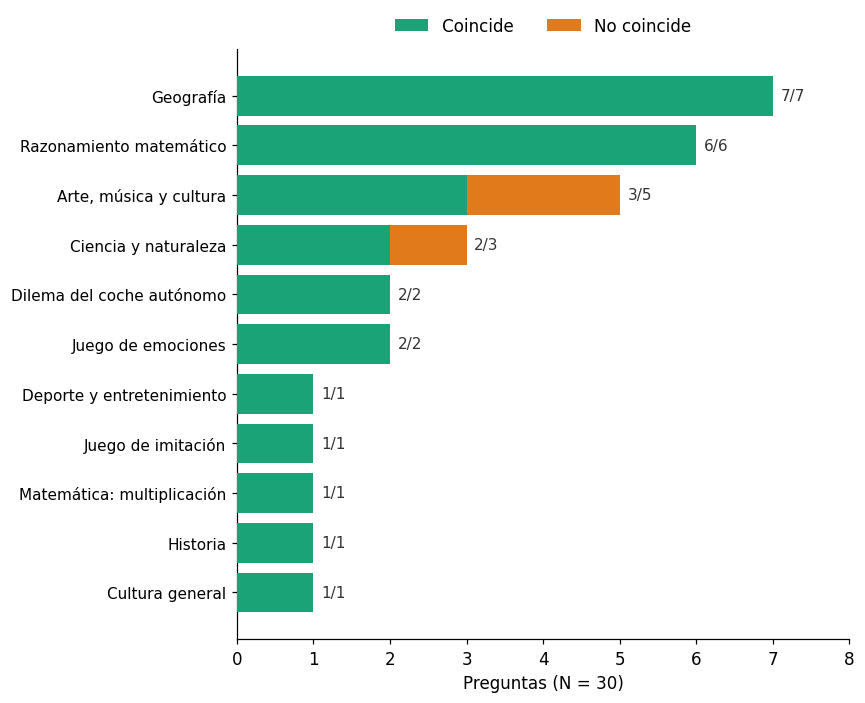

Coincidencia Rocha vs IA: 27/30 = 90%


In [3]:
# Datos de la comparacion Coincide / No coincide (27/30 = 90%).
# 'Reconocimiento musical' (0/2) es parte de 'Arte, musica y cultura' (3/3),
# asi que se fusionan: Arte, musica y cultura = 3/5.
cats = [
    ("Geografía",7,7),("Razonamiento matemático",6,6),("Arte, música y cultura",3,5),
    ("Ciencia y naturaleza",2,3),("Dilema del coche autónomo",2,2),("Juego de emociones",2,2),
    ("Deporte y entretenimiento",1,1),("Juego de imitación",1,1),
    ("Matemática: multiplicación",1,1),("Historia",1,1),("Cultura general",1,1),
]
dfc = pd.DataFrame(cats, columns=["categoria","coincide","total"])
dfc["no_coincide"] = dfc["total"] - dfc["coincide"]
dfc = dfc.iloc[::-1].reset_index(drop=True)  # orden como el ejemplo (mayor arriba)

fig, ax = plt.subplots(figsize=(8,6.5))
y = np.arange(len(dfc))
ax.barh(y, dfc["coincide"], color=VERDE, zorder=3, label="Coincide")
ax.barh(y, dfc["no_coincide"], left=dfc["coincide"], color=NARANJA, zorder=3, label="No coincide")
for i,(c,t) in enumerate(zip(dfc["coincide"], dfc["total"])):
    ax.text(t+0.1, i, f"{c}/{t}", va="center", fontsize=10, color="#333")
ax.set_yticks(y); ax.set_yticklabels(dfc["categoria"], fontsize=10)
co, to = dfc["coincide"].sum(), dfc["total"].sum()
ax.set_xlabel(f"Preguntas (N = {to})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,1.08), ncol=2, frameon=False, fontsize=11)
ax.set_xlim(0, dfc["total"].max()+1)
plt.tight_layout(); plt.show()
print(f"Coincidencia Rocha vs IA: {co}/{to} = {100*co/to:.0f}%")

## 3. Datos por turno

Se arma una tabla con el tiempo de cada etapa en cada pregunta, cruzando los
CSV por el **texto de la frase** (los relojes de Pi y PC están desfasados, pero
la frase es la misma clave). Esta tabla alimenta las líneas de tiempo siguientes.

In [4]:
import csv, re
def norm(s): return s.strip().lower()[:40]

# STT/SER/TER por frase (PC)
mod_por_frase = {}
with open(ruta("modulos_pc.csv"), encoding="utf-8", errors="replace") as f:
    r = csv.reader(f); next(r)
    for row in r:
        if len(row) > 5:
            try:
                mod_por_frase[norm(row[5])] = {
                    "stt": float(row[2]) if row[2] else np.nan,
                    "ser": float(row[3]) if row[3] else np.nan,
                    "ter": float(row[4]) if row[4] else np.nan}
            except ValueError: pass

# ventana FER por turno (del log, en orden de aparicion)
fer_vent = []
try:
    log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
    fer_vent = [float(m.group(1))*1000 for m in re.finditer(r"FER: \d+ cuadros en ([\d.]+) s", log)]
except FileNotFoundError: pass

# TTS por turno (en orden; tts.csv no trae texto)
tts_vals = pd.to_numeric(tts["t_tts_ms"], errors="coerce").dropna().tolist()

filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for i, ln in enumerate(f):
        partes = ln.rstrip("\n").split(",")
        texto = partes[-1].strip()
        nums = []
        for x in partes:
            try: nums.append(float(x))
            except ValueError: pass
        ei = next((j for j,v in enumerate(nums) if v > 1e9), None)
        if ei is None or ei < 3: continue
        m = mod_por_frase.get(norm(texto), {"stt":np.nan,"ser":np.nan,"ter":np.nan})
        filas.append({
            "pregunta": len(filas)+1,
            "STT": m["stt"], "SER": m["ser"], "TER": m["ter"],
            "afectiva": nums[0]*1000 if nums[0]*1000 < 3000 else np.nan,
            "LLM": nums[ei-1],
            "TTS": tts_vals[i] if i < len(tts_vals) else np.nan,
            "FER": fer_vent[i] if i < len(fer_vent) else np.nan,
        })
dft = pd.DataFrame(filas)
# por nodo
dft["communication_node"] = dft[["STT","TTS"]].sum(axis=1, min_count=1)
dft["orchestrator_node"]  = dft[["afectiva","LLM"]].sum(axis=1, min_count=1)
dft["expression_faces_node"] = dft["FER"]
print(f"{len(dft)} turnos."); dft.head()

32 turnos.


,pregunta,STT,SER,TER,afectiva,LLM,TTS,FER,communication_node,orchestrator_node,expression_faces_node
0,1,29.4,242.5,18.5,100.0,206.9,1427.8,1600.0,1457.2,306.9,1600.0
1,2,24.7,128.0,15.6,100.0,417.3,1199.8,29200.0,1224.5,517.3,29200.0
2,3,33.8,158.6,20.4,0.0,366.8,1801.1,6500.0,1834.9,366.8,6500.0
3,4,92.6,228.6,20.2,NaN,474.9,2496.6,7600.0,2589.2,474.9,7600.0
4,5,129.7,204.1,20.5,0.0,345.5,995.8,11200.0,1125.5,345.5,11200.0


## 4. Línea de tiempo por nodo

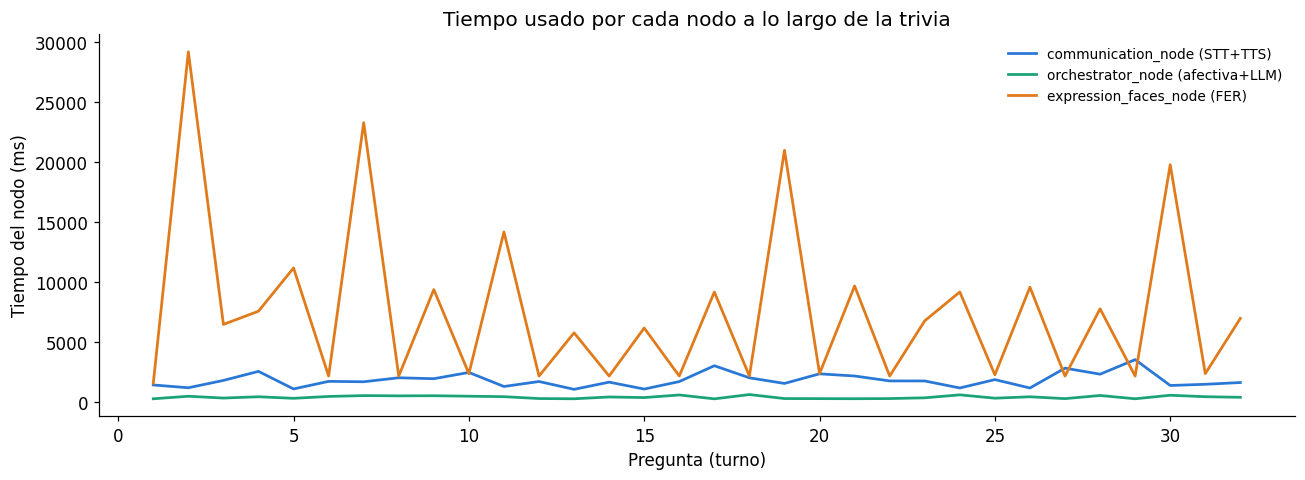

moving_control_node (carrito): no interviene en la trivia.


In [5]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["communication_node"], color=AZUL, lw=1.8, label="communication_node (STT+TTS)")
ax.plot(x, dft["orchestrator_node"], color=VERDE, lw=1.8, label="orchestrator_node (afectiva+LLM)")
ax.plot(x, dft["expression_faces_node"], color=NARANJA, lw=1.8, label="expression_faces_node (FER)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo del nodo (ms)")
ax.set_title("Tiempo usado por cada nodo a lo largo de la trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("moving_control_node (carrito): no interviene en la trivia.")

## 5. Línea de tiempo — percepción emocional (TER, FER, SER)

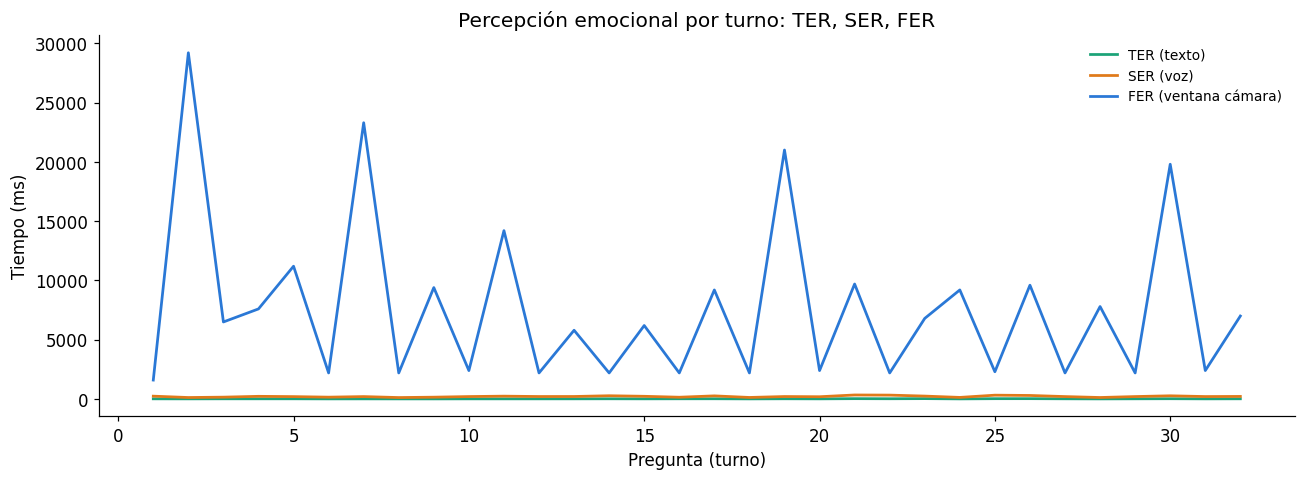

In [6]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["TER"], color=VERDE, lw=1.8, label="TER (texto)")
ax.plot(x, dft["SER"], color=NARANJA, lw=1.8, label="SER (voz)")
ax.plot(x, dft["FER"], color=AZUL, lw=1.8, label="FER (ventana cámara)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_title("Percepción emocional por turno: TER, SER, FER")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 6. Línea de tiempo — capa afectiva con sus entradas

La capa afectiva (PULSE+ROSE+AEB) junto con sus tres entradas de percepción
(TER, SER, FER). Se ve que la afectiva es casi instantánea (aritmética) frente
al tiempo que tardan los clasificadores que la alimentan.

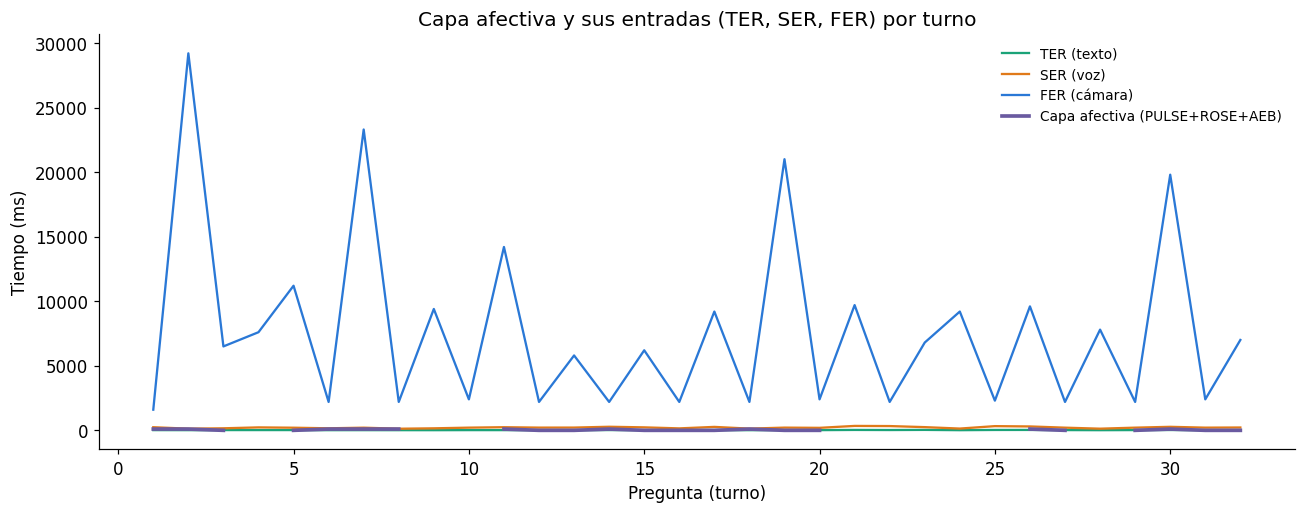

Capa afectiva: promedio 41.67 ms (es aritmética)


In [7]:
fig, ax = plt.subplots(figsize=(12,4.8))
x = dft["pregunta"]
ax.plot(x, dft["TER"], color=VERDE, lw=1.5, label="TER (texto)")
ax.plot(x, dft["SER"], color=NARANJA, lw=1.5, label="SER (voz)")
ax.plot(x, dft["FER"], color=AZUL, lw=1.5, label="FER (cámara)")
ax.plot(x, dft["afectiva"], color="#6a5aa0", lw=2.4, label="Capa afectiva (PULSE+ROSE+AEB)")
ax.fill_between(x, 0, dft["afectiva"], color="#6a5aa0", alpha=0.12)
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_title("Capa afectiva y sus entradas (TER, SER, FER) por turno")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"Capa afectiva: promedio {dft['afectiva'].mean():.2f} ms (es aritmética)")

## 7. Línea de tiempo — STT, TTS y LLM durante la trivia

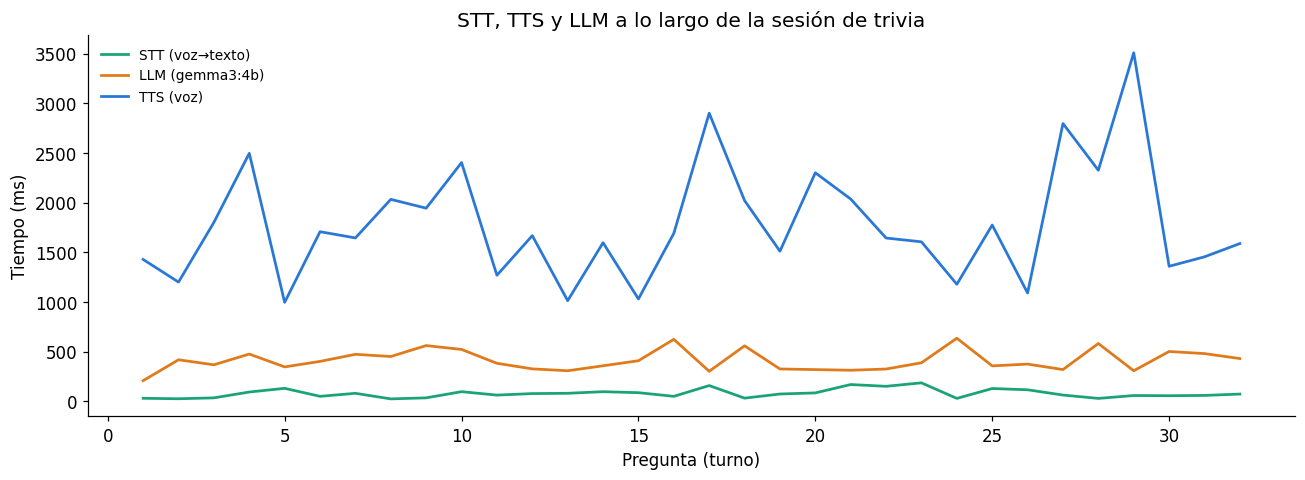

In [8]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["STT"], color=VERDE, lw=1.8, label="STT (voz→texto)")
ax.plot(x, dft["LLM"], color=NARANJA, lw=1.8, label="LLM (gemma3:4b)")
ax.plot(x, dft["TTS"], color=AZUL, lw=1.8, label="TTS (voz)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_title("STT, TTS y LLM a lo largo de la sesión de trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 8. Tokens del LLM

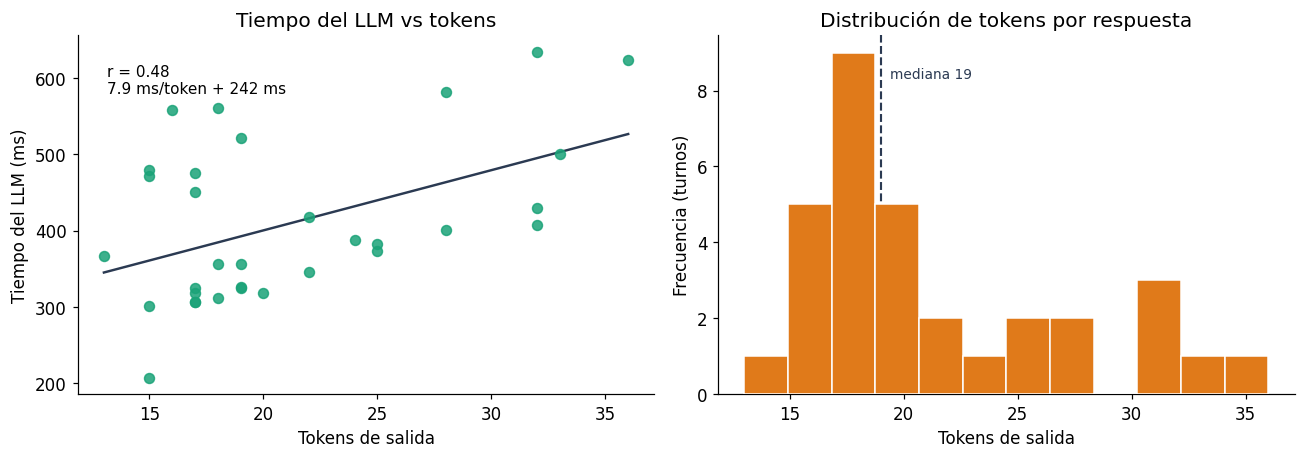

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12,4.3))
x = turnos["tokens_salida"].values; yv = turnos["t_llm_ms"].values
axs[0].scatter(x, yv, color=VERDE, s=42, alpha=0.85, zorder=3)
if len(x) > 2:
    b,a = np.polyfit(x,yv,1); xs=np.array([x.min(),x.max()])
    axs[0].plot(xs, a+b*xs, color=GRIS, lw=1.6)
    r = np.corrcoef(x,yv)[0,1]
    axs[0].text(0.05,0.92,f"r = {r:.2f}\n{b:.1f} ms/token + {a:.0f} ms",
                transform=axs[0].transAxes, va="top", fontsize=10)
axs[0].set_xlabel("Tokens de salida"); axs[0].set_ylabel("Tiempo del LLM (ms)")
axs[0].set_title("Tiempo del LLM vs tokens")
axs[1].hist(x, bins=12, color=NARANJA, zorder=3, edgecolor="white")
axs[1].axvline(np.median(x), color=GRIS, lw=1.4, ls="--")
axs[1].text(np.median(x)+0.4, axs[1].get_ylim()[1]*0.88, f"mediana {np.median(x):.0f}", fontsize=9, color=GRIS)
axs[1].set_xlabel("Tokens de salida"); axs[1].set_ylabel("Frecuencia (turnos)")
axs[1].set_title("Distribución de tokens por respuesta")
plt.tight_layout(); plt.show()

## 9. Recursos de la Raspberry Pi (de inicio a fin)

CPU total, proceso de cámara (FER), temperatura y RAM durante la sesión.

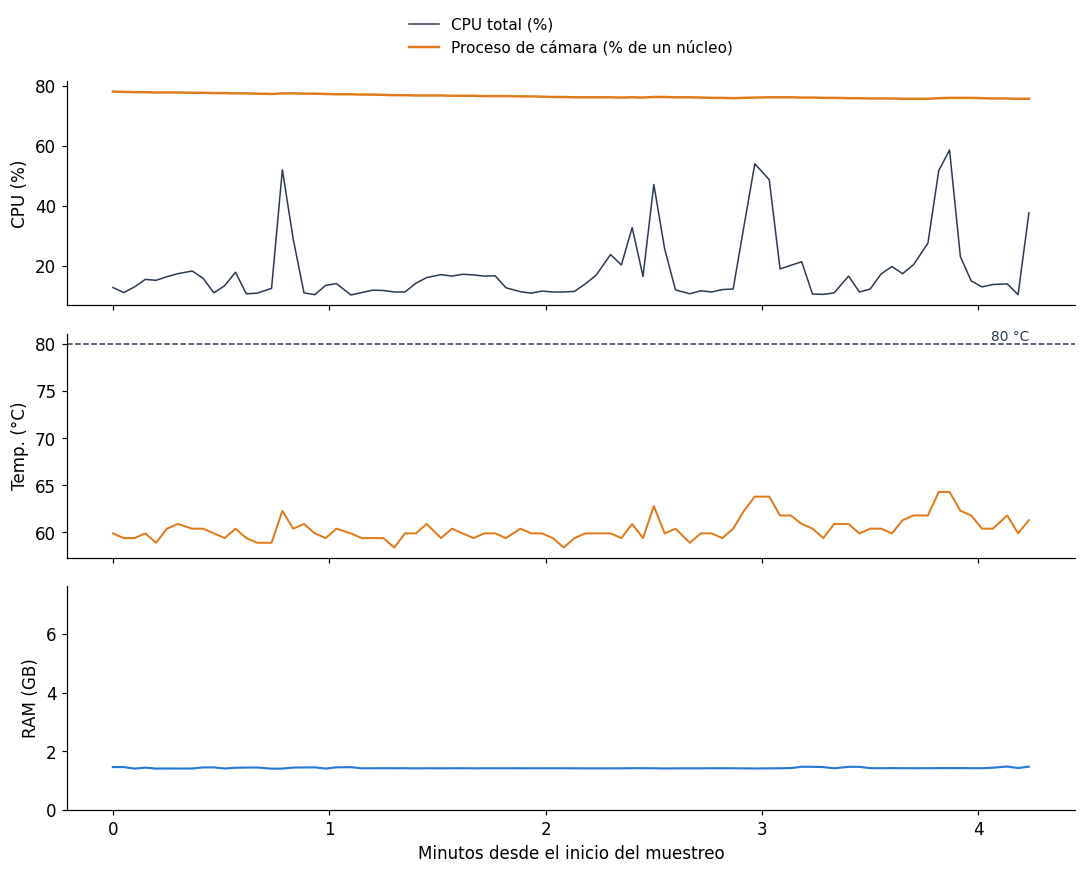

Recursos:
  CPU total:  mediana 14.1%  max 58.7%
  CPU camara: mediana 76.4%  max 78.2%
  RAM usada:  mediana 1462 MB  max 1521 MB


In [10]:
tiene_temp = (sis["temp_c"] > 0).any()
ram_gb = sis["ram_usada_mb"] / 1024
ram_total_gb = sis["ram_total_mb"].iloc[0]/1024 if "ram_total_mb" in sis.columns else 8

fig, axs = plt.subplots(3, 1, figsize=(10,8), sharex=True)
# (1) CPU total + camara
axs[0].plot(sis["min"], sis["cpu_total_pct"], color=GRIS, lw=1, label="CPU total (%)")
axs[0].plot(sis["min"], sis["cpu_camara_pct"], color=NARANJA, lw=1.6, label="Proceso de cámara (% de un núcleo)")
axs[0].set_ylabel("CPU (%)")
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5,1.35), ncol=1, frameon=False, fontsize=10)
# (2) Temperatura
if tiene_temp:
    axs[1].plot(sis["min"], sis["temp_c"], color=NARANJA, lw=1.3)
    axs[1].axhline(80, color=GRIS, ls="--", lw=1)
    axs[1].text(sis["min"].max(), 80.4, "80 °C", ha="right", fontsize=9, color=GRIS)
    axs[1].set_ylabel("Temp. (°C)")
else:
    axs[1].text(0.5,0.5,"Temperatura no capturada en esta corrida\n(bug del recolector ya corregido; lectura directa 73.5 °C, pico ~80 °C)",
                transform=axs[1].transAxes, ha="center", va="center", fontsize=10, color=ROJO)
    axs[1].set_ylabel("Temp. (°C)"); axs[1].set_yticks([])
# (3) RAM
axs[2].plot(sis["min"], ram_gb, color=AZUL, lw=1.4)
axs[2].set_ylabel("RAM (GB)"); axs[2].set_ylim(0, ram_total_gb)
axs[2].set_xlabel("Minutos desde el inicio del muestreo")
plt.tight_layout(); plt.show()

print("Recursos:")
print(f"  CPU total:  mediana {sis['cpu_total_pct'].median():.1f}%  max {sis['cpu_total_pct'].max():.1f}%")
print(f"  CPU camara: mediana {sis['cpu_camara_pct'].median():.1f}%  max {sis['cpu_camara_pct'].max():.1f}%")
print(f"  RAM usada:  mediana {sis['ram_usada_mb'].median():.0f} MB  max {sis['ram_usada_mb'].max():.0f} MB")

## 10. Tabla resumen (trivia)

In [11]:
def prom1(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return round(s.mean(),1) if len(s) else np.nan

tabla = []
for nombre, serie, unidad, nodo in [
    ("STT (voz→texto)", mod["t_stt_ms"], "ms", "communication / PC"),
    ("SER (emoción voz)", mod["t_ser_ms"], "ms", "communication / PC"),
    ("TER (emoción texto)", mod["t_ter_ms"], "ms", "communication / PC"),
    ("Afectiva PULSE+ROSE+AEB", turnos["afectiva_ms"], "ms", "orchestrator / Pi"),
    ("Respuesta LLM", turnos["t_llm_ms"], "ms", "orchestrator / Pi→PC"),
    ("Síntesis TTS", tts["t_tts_ms"], "ms", "communication / PC"),
    ("Tokens de salida", turnos["tokens_salida"], "tokens", "orchestrator"),
    ("CPU total Pi", sis["cpu_total_pct"], "%", "Raspberry"),
    ("CPU cámara/FER", sis["cpu_camara_pct"], "%", "expression / IMX500"),
    ("RAM usada Pi", sis["ram_usada_mb"], "MB", "Raspberry"),
]:
    tabla.append([nombre, prom1(serie), unidad, nodo])
df = pd.DataFrame(tabla, columns=["Indicador","Promedio","Unidad","Nodo / máquina"])
print("Coincidencia Rocha vs IA: 27/30 = 90%\n")
df

Coincidencia Rocha vs IA: 27/30 = 90%



,Indicador,Promedio,Unidad,Nodo / máquina
0,STT (voz→texto),78.6,ms,communication / PC
1,SER (emoción voz),216.8,ms,communication / PC
2,TER (emoción texto),20.0,ms,communication / PC
3,Afectiva PULSE+ROSE+AEB,41.7,ms,orchestrator / Pi
4,Respuesta LLM,410.2,ms,orchestrator / Pi→PC
5,Síntesis TTS,1756.2,ms,communication / PC
6,Tokens de salida,21.2,tokens,orchestrator
7,CPU total Pi,18.3,%,Raspberry
8,CPU cámara/FER,76.7,%,expression / IMX500
9,RAM usada Pi,1469.6,MB,Raspberry
